# RWB «Отгрузки без простоев» — решение

Прогноз `target_1h` на 8 получасов вперёд для 1000 маршрутов от точки 01.11.2025 10:30. Метрика — **WAPE + |Relative Bias|**, меньше — лучше.

| | Score |
|---|---|
| Baseline организаторов (Ridge), на нашей валидации | 0.3674 |
| Это решение, валидация (14 дней, перекрёстно) | 0.329 |
| Это решение, валидация (веса подобраны на всех 14 днях) | 0.327 |
| **Лидерборд, `submissions/ensemble_v1.csv`** | **0.324** |

Ноутбук — «тонкий»: весь код живёт в `src/rwb/` и `scripts/`, здесь он вызывается и объясняется. Так ноутбук не расходится с кодом, который гоняют из командной строки.

**Как запустить.** Окружение из `requirements.txt` (XGBoost работает на GPU, `device=cuda`; LightGBM — на CPU; MLP — PyTorch на GPU).
Тяжёлые шаги (обучение трёх моделей, ~1.5 часа на RTX 4060 Laptop) берут сохранённые предсказания из `models/oof/`, если они есть. Чтобы пересчитать всё с нуля, поставьте `RETRAIN = True`.

**Что внутри и в каком порядке**

1. Данные и метрика
2. Ключевое наблюдение: `target_1h` — сумма двух получасов, их можно восстановить
3. Валидация без утечек: 14 точек прогноза в 10:30
4. Признаки и цель обучения
5. Три модели и их результаты
6. Ансамбль: веса и калибровка, подобранные перекрёстно
7. Разбор ошибок: что ещё можно улучшить и почему упёрлись в шум
8. Итоговый прогноз и файл посылки
9. Что не сработало

In [1]:
import sys, json, logging, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent  # запуск из notebooks/
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))

from rwb.data import HORIZON, STEP, load_panel, make_submission, wape_rbias
from rwb.features import DAY, WEEK, build, cumsums, half_hour_shipments
from rwb.backtest import default_folds, run, score_origins, truth_for
from rwb.models import GBMConfig, gbm_fit_predict, naive

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(name)s %(message)s", datefmt="%H:%M:%S")
RETRAIN = False          # True — переобучить модели, не используя сохранённые предсказания
OOF = ROOT / "models/oof"
OOF.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)

## 1. Данные и метрика

Train — 4 630 000 строк: 1000 маршрутов × 4630 получасов с 28.07.2025 по 01.11.2025 10:30. Данные удобно держать как матрицы «маршрут × время»: `y` для `target_1h` и `s` для шести статусов. Так лаги, окна и «тот же получас неделю назад» — это просто сдвиги по оси времени.

In [2]:
panel = load_panel()        # кэшируется в data/processed/panel.npz
print(f"маршрутов R={panel.n_routes}, моментов T={panel.n_times}, "
      f"период {panel.times[0]} — {panel.times[-1]}, шаг {STEP}")
print("y (R,T):", panel.y.shape, " s (6,R,T):", panel.s.shape, " test:", panel.test.shape)
print("пропусков в y:", int(np.isnan(panel.y).sum()))
desc = pd.DataFrame({"target_1h": np.nan_to_num(panel.y).ravel()}).describe().T
desc

маршрутов R=1000, моментов T=4630, период 2025-07-28 00:00:00 — 2025-11-01 10:30:00, шаг 0 days 00:30:00
y (R,T): (1000, 4630)  s (6,R,T): (6, 1000, 4630)  test: (8000, 3)
пропусков в y: 0


,count,mean,std,min,25%,50%,75%,max
target_1h,4630000.0,261242.125,169082.578125,0.0,138990.0,235769.0,355175.0,10831337.0


Метрика считается по всем 8000 точкам сразу: $\text{WAPE} = \frac{\sum|y-\hat y|}{\sum y}$ оценивает ошибки отдельных прогнозов, $|\text{RelBias}| = \frac{|\sum \hat y - \sum y|}{\sum y}$ — суммарное завышение или занижение объёма. Наша реализация — `rwb.data.wape_rbias`:

In [3]:
import inspect
print(inspect.getsource(wape_rbias))

def wape_rbias(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    y_true = np.asarray(y_true, dtype=np.float64).ravel()
    y_pred = np.asarray(y_pred, dtype=np.float64).ravel()
    denom = y_true.sum()
    if denom <= 0:
        raise ValueError("Sum of y_true must be positive")
    return float(np.abs(y_pred - y_true).sum() / denom + abs(y_pred.sum() / denom - 1))



## 2. Ключевое наблюдение: получасовые отгрузки восстанавливаются

`target_1h[t]` — объём за **час**, заканчивающийся в `t`, а шаг данных — **полчаса**. Значит `y[t] = x[t] + x[t-1]`, где `x` — объём за получас. Знакопеременная сумма $A[t] = y[t] - A[t-1]$ даёт $x[t] = A[t] + (-1)^t c$ с одной неизвестной константой `c` на маршрут. Условие $x \ge 0$ зажимает `c` с двух сторон, и в этих данных границы сходятся с точностью до единиц. Берём середину границ по скользящему окну в 7 дней — только прошлое, без заглядывания вперёд (`rwb.features.half_hour_shipments`).

Почему это важно: на горизонте +30 минут половина ответа (`x[o]`) уже известна точно, и WAPE там 0.23 против 0.33 на дальних горизонтах.

|x[t]+x[t-1] - y[t]|: медиана 0.0, 99% 4.5, средний y 261242


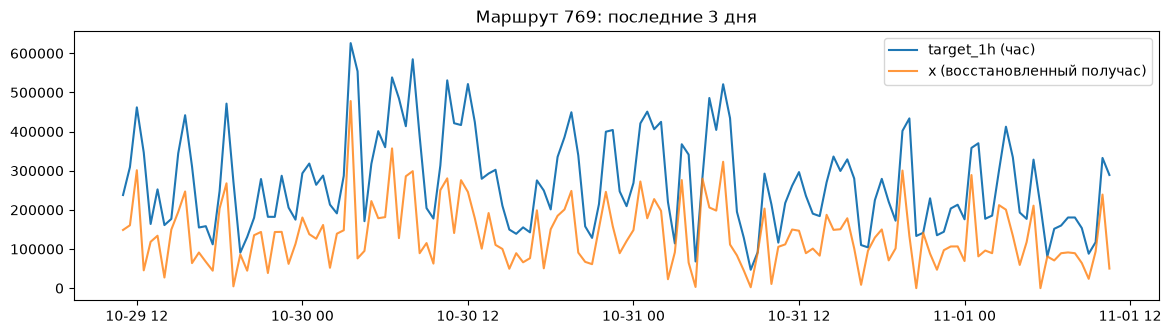

In [4]:
cums = cumsums(panel)
x = cums.x
recon = x[:, 1:] + x[:, :-1]
err = np.abs(recon - np.nan_to_num(panel.y[:, 1:]))
print(f"|x[t]+x[t-1] - y[t]|: медиана {np.median(err):.1f}, 99% {np.quantile(err, .99):.1f}, "
      f"средний y {np.nanmean(panel.y):.0f}")

r = int(np.argsort(np.nan_to_num(panel.y).mean(1))[500])   # маршрут со срединным объёмом
sl = slice(panel.n_times - 3 * DAY, panel.n_times)
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(panel.times[sl], panel.y[r, sl], label="target_1h (час)")
ax.plot(panel.times[sl], x[r, sl], label="x (восстановленный получас)", alpha=.8)
ax.set_title(f"Маршрут {panel.routes[r]}: последние 3 дня"); ax.legend(); plt.show()

## 3. Валидация без утечек

Тест — одна точка прогноза (суббота 10:30) и 8 шагов вперёд для всех маршрутов. Валидация повторяет это: берём 10:30 в каждый из 14 предыдущих дней, две недели — два фолда. Модель фолда обучается **только на метках до первой точки фолда** (`label_cutoff`), поэтому ни одна валидационная метка не попадает в обучение. Score — среднее по дням, в каждом дне метрика считается по всем 8000 точкам, как на лидерборде.

Отдельный тест `tests/test_features.py` портит будущее мусором и проверяет, что признаки не меняются.

In [5]:
folds = default_folds(panel)
for f in folds:
    days = [str(panel.times[o].date()) for o in f.val_origins]
    print(f"{f.name}: обучение на метках до {panel.times[f.label_cutoff]}, валидация в 10:30 на {days[0]} … {days[-1]}")

rows = []
for kind, descr in [("last", "последнее значение"), ("day", "тот же получас вчера"), ("week", "тот же получас неделю назад"),
                    ("slot7", "среднее того же получаса за 7 дней"), ("base", "сезонная база: 0.5·среднее за сутки + 0.5·slot7")]:
    sc = []
    for f in folds:
        sc += score_origins(naive(panel, f.val_origins, kind, cums), truth_for(panel, f.val_origins))
    rows.append((kind, descr, np.mean(sc)))
pd.DataFrame(rows, columns=["naive", "что это", "score"]).round(4)

fold0: обучение на метках до 2025-10-25 10:30:00, валидация в 10:30 на 2025-10-25 … 2025-10-31
fold1: обучение на метках до 2025-10-18 10:30:00, валидация в 10:30 на 2025-10-18 … 2025-10-24


,naive,что это,score
0,last,последнее значение,0.5021
1,day,тот же получас вчера,0.4976
2,week,тот же получас неделю назад,0.5041
3,slot7,среднее того же получаса за 7 дней,0.3796
4,base,сезонная база: 0.5·среднее за сутки + 0.5·slot7,0.3638


## 4. Признаки и цель обучения

Для каждого горизонта `h` строится таблица «маршрут × точка прогноза». Всё — только из данных до точки `o` (`rwb.features.build`):

- лаги `y`, разности, скользящие средние и std по окнам от 1 часа до 2 недель;
- тот же получас в прошлые 1–7 дней и 1–4 недели, медианы и квартили по ним;
- восстановленные получасы `x`: лаги, окна, и `x[o]` как известная половина ответа для `h=1`;
- статусы 1–6: окна, суммы за текущий/предыдущий час и их отношения к объёму;
- календарь: получас и день недели точки прогноза и целевого момента.

**Цель.** Модель учит не `y`, а поправку к сезонной базе в долях недельного уровня маршрута: $(y - \text{base}) / \text{scale}$, где `scale` — средняя отгрузка за неделю + 1. Все признаки тоже делятся на `scale`. Благодаря этому маршруты с объёмом 10 000 и 1 000 000 учатся одной моделью. Взвешенный `scale` L1 по такой цели **равен числителю WAPE**, то есть модель оптимизирует ровно то, что оценивается.

In [6]:
o = np.array([folds[0].val_origins[0]])
X, names, base = build(panel, cums, o, h=1)
print(f"h=1: матрица {X.shape} (маршрутов × признаков), {len(names)} признаков")
groups = {}
for n in names:
    groups.setdefault(n.split("_")[0], []).append(n)
pd.Series({k: len(v) for k, v in groups.items()}).sort_values(ascending=False).to_frame("признаков").T

h=1: матрица (1000, 119) (маршрутов × признаков), 119 признаков


,lag,x,rm,rs,sd,s5,s2,s1,s4,s3,...,dow,yday,lweek,slot14,d2,log,route,d1,slotw4,base
признаков,13,13,9,8,7,5,5,5,5,5,...,2,2,2,1,1,1,1,1,1,1


## 5. Модели

Три разных по природе модели, каждая предсказывает 8 горизонтов. Конфигурации — те же, что в командах из README; здесь они записаны явно, чтобы было видно, что обучалось.

| Имя | Что | Чем отличается |
|---|---|---|
| `xgb_lr` | XGBoost (GPU), по модели на горизонт, L1 | Основная: 900 деревьев, lr 0.02, 63 листа, 28 дней истории, точки прогноза каждый час |
| `lgbm_huber` | LightGBM (CPU), Huber | Сильнее регуляризована: 31 лист, ≥1000 объектов в листе |
| `mlp_big` | MLP (GPU), loss = WAPE по батчу | Другой класс модели: сырые окна истории + эмбеддинги маршрута, получаса, дня недели |

Функция ниже либо загружает сохранённые предсказания фолдов из `models/oof/<имя>.npz`, либо обучает модель (при `RETRAIN=True` или если файла нет).

In [7]:
CONFIGS = {
    "xgb_lr": GBMConfig(lib="xgb", days=28, stride=2, rounds=900, lr=0.02, leaves=63, min_child=200),
    "lgbm_huber": GBMConfig(lib="lgbm", days=28, stride=4, rounds=400, lr=0.05, leaves=31, min_child=1000,
                            objective="huber", extra={"num_threads": 8, "alpha": 1.0}),
}

def fit_predict(name, label_cutoff, origins):
    # Одна точка входа для бустингов и MLP: обучить на метках до label_cutoff, предсказать в origins.
    if name in CONFIGS:
        return gbm_fit_predict(panel, cums, label_cutoff, origins, CONFIGS[name])
    from rwb.nn import NNConfig, nn_fit_predict
    return nn_fit_predict(panel, cums, label_cutoff, origins,
                          NNConfig(days=84, recent=192, hidden=1024, dropout=0.2, epochs=12))

def backtest(name):
    path = OOF / f"{name}.npz"
    if path.exists() and not RETRAIN:
        z = np.load(path)
        return {f.name: z[f"pred_{f.name}"] for f in folds}, {f.name: z[f"truth_{f.name}"] for f in folds}
    t0 = time.time()
    res = run(panel, folds, lambda f: fit_predict(name, f.label_cutoff, f.val_origins))
    np.savez_compressed(path, **{f"pred_{k}": v for k, v in res.preds.items()}, **{f"truth_{k}": v for k, v in res.truth.items()})
    print(f"{name}: {time.time() - t0:.0f} c")
    return res.preds, res.truth

MODELS = ["xgb_lr", "lgbm_huber", "mlp_big"]
preds, truth = {}, None
for name in MODELS:
    preds[name], truth = backtest(name)

rows = []
for name in MODELS:
    raw = {f: np.mean(score_origins(preds[name][f], truth[f])) for f in truth}
    rows.append({"model": name, **{f"{f} (без калибровки)": v for f, v in raw.items()}, "mean": np.mean(list(raw.values()))})
pd.DataFrame(rows).set_index("model").round(4)

,fold0 (без калибровки),fold1 (без калибровки),mean
model,,,
xgb_lr,0.3346,0.3433,0.3390
lgbm_huber,0.3291,0.3276,0.3284
mlp_big,0.3392,0.3454,0.3423


Без калибровки XGBoost и MLP хуже, чем кажется по ансамблю: L1 даёт **медиану**, а распределение отгрузок скошено вправо, поэтому сумма прогнозов занижена примерно на 2% и вторая часть метрики штрафует. Huber ближе к среднему, ему калибровка почти не нужна. Один общий множитель на все прогнозы — это и есть калибровка, подбирается в следующем шаге вместе с весами.

## 6. Ансамбль

Веса трёх моделей (на симплексе, через softmax) и общий множитель подбираются минимизацией метрики на предсказаниях валидации (`scripts/ensemble.py`). Чтобы не обманывать себя, оценка **перекрёстная**: веса подобраны на одной неделе, метрика посчитана на другой, и наоборот. Итоговые веса для посылки подбираются на всех 14 днях.

Подбирается всего 4 числа (3 доли и множитель) по 14 × 8000 точкам, подгонки под тест здесь нет: тестовые метки не используются нигде.

In [8]:
from ensemble import fit_weights     # scripts/ensemble.py

import itertools
fold_names = sorted(truth)
P = {f: np.stack([preds[n][f] for n in MODELS], axis=-1) for f in fold_names}
cross = {}
for fit_f, eval_f in itertools.permutations(fold_names, 2):
    w, _ = fit_weights(P[fit_f], truth[fit_f], per_h_scale=False)
    cross[f"веса с {fit_f} → оценка на {eval_f}"] = (np.mean(score_origins(P[eval_f] @ w, truth[eval_f])), w)
for k, (s, w) in cross.items():
    print(f"{k}: {s:.4f}   веса {np.round(w, 3)}")
P_all = np.concatenate([P[f] for f in fold_names]); Y_all = np.concatenate([truth[f] for f in fold_names])
W, _ = fit_weights(P_all, Y_all, per_h_scale=False)
print(f"\nперекрёстно: {np.mean([v[0] for v in cross.values()]):.4f}")
print(f"веса на всех 14 днях: {dict(zip(MODELS, np.round(W, 3)))}, сумма = множитель калибровки = {W.sum():.3f}")
print(f"на тех же 14 днях (оптимистично): {np.mean(score_origins(P_all @ W, Y_all)):.4f}")

веса с fold0 → оценка на fold1: 0.3286   веса [0.813 0.11  0.092]
веса с fold1 → оценка на fold0: 0.3296   веса [0.612 0.147 0.266]



перекрёстно: 0.3291
веса на всех 14 днях: {'xgb_lr': np.float64(0.673), 'lgbm_huber': np.float64(0.261), 'mlp_big': np.float64(0.086)}, сумма = множитель калибровки = 1.020
на тех же 14 днях (оптимистично): 0.3269


## 7. Разбор ошибок

Разложим метрику ансамбля по дням на WAPE и |bias|. WAPE стабилен (0.30–0.32), а смещение скачет от −0.046 до +0.040 в зависимости от дня: суммарный объём дня предсказать заранее не получается, и это задаёт потолок. Отдельная модель суммарного объёма сети, сглаживание по горизонтам, поправки на уровне маршрутов — проверены, не помогают (см. раздел 9).

In [9]:
origins = np.concatenate([f.val_origins for f in folds])
blend = P_all @ W
rows = []
for i, o in enumerate(origins):
    p, y = blend[i], Y_all[i]
    wape = np.abs(p - y).sum() / y.sum(); rb = (p.sum() - y.sum()) / y.sum()
    rows.append({"день": panel.times[o].strftime("%Y-%m-%d %a"), "WAPE": wape, "RelBias": rb, "score": wape + abs(rb)})
df = pd.DataFrame(rows).set_index("день")
print(f"средний WAPE {df.WAPE.mean():.4f}  средний |bias| {df.RelBias.abs().mean():.4f}  score {df.score.mean():.4f}")
print("WAPE по горизонтам:", np.round([np.mean([np.abs(blend[i][:, h] - Y_all[i][:, h]).sum() / Y_all[i][:, h].sum()
                                                 for i in range(len(origins))]) for h in range(HORIZON)], 3))
df.round(4)

средний WAPE 0.3147  средний |bias| 0.0122  score 0.3269
WAPE по горизонтам: [0.23  0.3   0.318 0.32  0.338 0.346 0.336 0.334]


,WAPE,RelBias,score
день,,,
2025-10-25 Sat,0.3205,0.0081,0.3286
2025-10-26 Sun,0.3233,-0.0018,0.3251
2025-10-27 Mon,0.3200,0.0000,0.3200
2025-10-28 Tue,0.3145,-0.0044,0.3189
2025-10-29 Wed,0.3219,0.0396,0.3615
2025-10-30 Thu,0.3044,0.0119,0.3163
2025-10-31 Fri,0.3173,0.0150,0.3323
2025-10-18 Sat,0.3162,-0.0026,0.3188
2025-10-19 Sun,0.3113,-0.0204,0.3316


## 8. Итоговый прогноз

Каждая модель обучается на всех данных (метки до 01.11.2025 10:30) и предсказывает 8 шагов от последней точки. Прогнозы смешиваются с весами `W` из раздела 6. Сохранённые тестовые прогнозы лежат в `models/oof/<имя>_test.npy`.

In [10]:
last = panel.n_times - 1
test_preds = []
for name in MODELS:
    path = OOF / f"{name}_test.npy"
    if path.exists() and not RETRAIN:
        test_preds.append(np.load(path))
    else:
        pred = fit_predict(name, last, np.array([last]))[0]
        np.save(path, pred); test_preds.append(pred)
final = np.stack(test_preds, axis=-1) @ W          # (R, 8)

sub = make_submission(panel, final)
out = ROOT / "submissions/solution_v1_notebook.csv"
sub.to_csv(out, index=False)
assert len(sub) == 8000 and set(sub["id"]) == set(panel.test["id"]) and (sub["y_pred"] >= 0).all() and np.isfinite(sub["y_pred"]).all()
print(f"{out.name}: {len(sub)} строк, сумма прогноза {sub.y_pred.sum():.3e}")
same_window_yday = np.nan_to_num(panel.y[:, last + 1 - DAY: last + 1 - DAY + HORIZON]).sum()
print(f"для сравнения, то же окно днём раньше: {same_window_yday:.3e}")
ref = ROOT / "submissions/ensemble_v1.csv"
if ref.exists():
    v1 = pd.read_csv(ref).set_index("id").loc[sub["id"], "y_pred"].to_numpy()
    print(f"отличие от ensemble_v1.csv (лидерборд 0.324): max |Δ|/y = {np.max(np.abs(v1 - sub.y_pred.to_numpy()) / (v1 + 1)):.2e}")
sub.head()

solution_v1_notebook.csv: 8000 строк, сумма прогноза 2.222e+09
для сравнения, то же окно днём раньше: 2.236e+09
отличие от ensemble_v1.csv (лидерборд 0.324): max |Δ|/y = 0.00e+00


,id,y_pred
0,0,106637.784329
1,1,139083.229259
2,2,171393.904083
3,3,165476.935694
4,4,153250.945537


## 9. Что не сработало

Проверено на той же валидации; всё упирается в плато 0.327–0.330. Ошибки моделей разных классов (деревья, MLP, Chronos-2) коррелируют на 0.95 — остаток это шум получасовых отгрузок, а не недоработка модели.

- **Очистка метки**: обрезка выбросов по квантилю маршрута, сглаживание соседними шагами, медианные признаки — хуже или так же.
- **Гиперпараметры**: окна 14–56 дней, шаг точек прогноза 1–4, листья 31–127, затухание весов по времени — разница в пределах 0.001.
- **Общие признаки по всей сети** (суммарный объём, его отношение к норме) и **накопленный остаток по статусам** — не дали прироста.
- **Одна модель на все горизонты** вместо восьми — хуже на 0.002.
- **Отдельная модель суммарного объёма сети** для снятия дневного смещения — предсказывает объём хуже, чем сумма маршрутных прогнозов.
- **Пост-обработка**: сглаживание прогнозов по горизонтам, веса ансамбля на каждый горизонт, множители и сдвиги по маршрутам — хуже перекрёстно.
- **AutoGluon / Chronos-2** (zero-shot, отдельное окружение Python 3.13): 0.355 сам по себе, в ансамбле вес ≈ 0.

Лидерборд — один день, а дневное смещение гуляет на ±0.01–0.05, поэтому разница между 0.324 на лидерборде и 0.327–0.329 на валидации — в пределах этого разброса.